## 1. Import libraries and configure paths


In [ ]:
from pathlib import Path
import re
import html
import json
from datetime import datetime

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)


INPUT_CSV = r"C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\Trustpilot_ABSA_dataset.csv"
OUTPUT_DIR = Path(r"C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output")

# Light preprocessing options
REMOVE_EMOJI = True
# LOWERCASE = False  
# REMOVE_PUNCTUATION = False

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output directory:", OUTPUT_DIR.resolve())

Output directory: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output


## 2. Define Trustpilot aspect columns

`General` / `General_text` describes the overall review sentiment.


In [ ]:
ASPECT_COLS = [
    "Information",
    "Product_features",
    "Item_quality",
    "App_experience",
    "Pricing",
    "Product_availability",
    "Payment",
    "Packaging",
    "Delivered_product_status",
    "Shipping",
    "Return_process",
    "Refund_process",
    "Customer_service",
    "Trust",
]

TEXT_COLS = ["Header", "Review"]

OPTIONAL_METADATA_COLS = [
    "Card_id",
    "Rating",
    "Location",
    "Date",
    "Total Review",
    "shop",
    "Year",
    "General",
    "General_text",
]

print("Number of aspects:", len(ASPECT_COLS))
print(ASPECT_COLS)

Number of aspects: 14
['Information', 'Product_features', 'Item_quality', 'App_experience', 'Pricing', 'Product_availability', 'Payment', 'Packaging', 'Delivered_product_status', 'Shipping', 'Return_process', 'Refund_process', 'Customer_service', 'Trust']


## 3. Load dataset



In [4]:
def resolve_input_path(path_like: str) -> Path:
    candidates = [
        Path(path_like),
        Path.cwd() / path_like,
        Path("/mnt/data") / path_like,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the input CSV. Tried:\n" + "\n".join(str(c) for c in candidates)
    )

input_path = resolve_input_path(INPUT_CSV)
print("Input file:", input_path.resolve())

df_raw = pd.read_csv(input_path)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Input file: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\Trustpilot_ABSA_dataset.csv
Dataset shape: (3500, 25)


,Card_id,Header,Review,Rating,Location,Date,Total Review,shop,Information,Product_features,Item_quality,App_experience,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust,General,Year,General_text
0,591ed0daa02b420900675219,Excellent and well organised,"Excellent and well organised, I will recommend this site to everyone",5,Britain (UK),2017-05-19,1 review,Zalando,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2017,Positive
1,5b7af35f14b7d805ec7389c4,Bizarre returns service.,NaN,1,Britain (UK),2018-08-20,3 reviews,Zalando,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,2018,Negative
2,6076f1f9f85d7508705c1b74,😀😁😁😁😁😁😁,great use 😁🤳,4,United States,2021-04-14,1 review,Wish,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2021,Positive
3,5fe77011755dc107e0cf497f,I have ordered jacket and then returned…,I have ordered jacket and then returned back. They are blocked amount on my card 2 times and nothing. 3 days i am tr...,1,Finland,2020-12-26,1 review,Zalando,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,2020,Negative
4,56b86e070000ff000938c154,Great service!!! So helpful personal,"My dress was broken, ordered a new one and sent an email to Nelly. Got my new dress 2 days later and it was perfect.",5,United States,2016-02-08,4 reviews,Nelly,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,2016,Positive


## 4. Validate required columns



In [5]:
required_cols = TEXT_COLS + ASPECT_COLS
missing_cols = [col for col in required_cols if col not in df_raw.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

available_metadata_cols = [col for col in OPTIONAL_METADATA_COLS if col in df_raw.columns]
print("All required columns are available.")
print("Available metadata columns:", available_metadata_cols)

All required columns are available.
Available metadata columns: ['Card_id', 'Rating', 'Location', 'Date', 'Total Review', 'shop', 'Year', 'General', 'General_text']


## 5. Light preprocessing functions

Included cleaning:

- HTML entity normalization,
- HTML tag removal,
- URL removal,
- control character removal,
- emoji removal,
- whitespace normalization.

Not applied by default:

- stopword removal,
- lemmatization,
- aggressive punctuation removal.


In [ ]:

EMOJI_PATTERN = re.compile(
    "["
    "\U0001F1E6-\U0001F1FF"  # flags
    "\U0001F300-\U0001F5FF"  # symbols & pictographs
    "\U0001F600-\U0001F64F"  # emoticons
    "\U0001F680-\U0001F6FF"  # transport & map symbols
    "\U0001F700-\U0001F77F"  # alchemical symbols
    "\U0001F780-\U0001F7FF"  # geometric shapes extended
    "\U0001F800-\U0001F8FF"  # supplemental arrows-C
    "\U0001F900-\U0001F9FF"  # supplemental symbols and pictographs
    "\U0001FA00-\U0001FA6F"  # chess symbols, symbols and pictographs extended-A
    "\U0001FA70-\U0001FAFF"  # symbols and pictographs extended-A continued
    "\U00002702-\U000027B0"  # dingbats
    "\U000024C2-\U0001F251"
    "\U0001F3FB-\U0001F3FF"  # skin tone modifiers
    "\u200d"                 # zero width joiner
    "\ufe0f"                 # variation selector-16
    "]+",
    flags=re.UNICODE,
)

URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
HTML_TAG_PATTERN = re.compile(r"<[^>]+>")
CONTROL_CHAR_PATTERN = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]")
WHITESPACE_PATTERN = re.compile(r"\s+")

# Optional punctuation removal pattern, disabled by default.
PUNCT_PATTERN = re.compile(r"[^\w\s]")


def contains_emoji(text) -> bool:
    if pd.isna(text):
        return False
    return bool(EMOJI_PATTERN.search(str(text)))


def remove_emoji(text: str) -> str:
    return EMOJI_PATTERN.sub(" ", text)


def light_clean_text(text, *, remove_emoji_flag=True, lowercase=False, remove_punctuation=False) -> str:
    """Apply light preprocessing suitable for transformer-based NLP models."""
    if pd.isna(text):
        return ""

    text = str(text)
    text = html.unescape(text)
    text = HTML_TAG_PATTERN.sub(" ", text)
    text = URL_PATTERN.sub(" ", text)
    text = CONTROL_CHAR_PATTERN.sub(" ", text)

    if remove_emoji_flag:
        text = remove_emoji(text)

    if lowercase:
        text = text.lower()

    if remove_punctuation:
        text = PUNCT_PATTERN.sub(" ", text)

    text = WHITESPACE_PATTERN.sub(" ", text).strip()
    return text


def combine_header_review(header, review) -> str:
    """Combine Header and Review without creating awkward empty punctuation."""
    header = "" if pd.isna(header) else str(header).strip()
    review = "" if pd.isna(review) else str(review).strip()

    if header and review:
        return f"{header}. {review}"
    if header:
        return header
    if review:
        return review
    return ""

## 6. Check emojis before cleaning



In [7]:
df = df_raw.copy()

df["text_raw"] = [
    combine_header_review(header, review)
    for header, review in zip(df["Header"], df["Review"])
]

emoji_mask_header = df["Header"].apply(contains_emoji)
emoji_mask_review = df["Review"].apply(contains_emoji)
emoji_mask_text = df["text_raw"].apply(contains_emoji)

print("Rows with emoji in Header:", int(emoji_mask_header.sum()))
print("Rows with emoji in Review:", int(emoji_mask_review.sum()))
print("Rows with emoji in combined text_raw:", int(emoji_mask_text.sum()))

emoji_examples = df.loc[emoji_mask_text, ["Card_id", "Header", "Review", "text_raw"]].head(10)
display(emoji_examples)

Rows with emoji in Header: 59
Rows with emoji in Review: 96
Rows with emoji in combined text_raw: 145


,Card_id,Header,Review,text_raw
2,6076f1f9f85d7508705c1b74,😀😁😁😁😁😁😁,great use 😁🤳,😀😁😁😁😁😁😁. great use 😁🤳
25,60ae97e3f9f4870b700f4cb4,Elsker at handle på Boozt,Elsker at handle på Boozt - gode rabatter og super service👍🏼,Elsker at handle på Boozt. Elsker at handle på Boozt - gode rabatter og super service👍🏼
41,6075e239f85d7508705a7cf6,Super god service👍🤗,NaN,Super god service👍🤗
76,60797344f85d75087060703f,🎉🌷💪,🎉🌷💪 Super Good !!!,🎉🌷💪. 🎉🌷💪 Super Good !!!
112,60d2074df9f48707eca7c622,Min favoritt net butikk.,Min favoritt net butikk.. rask.. godt qualitet.. love to shop at Boozt.com❤️❤️❤️,Min favoritt net butikk.. Min favoritt net butikk.. rask.. godt qualitet.. love to shop at Boozt.com❤️❤️❤️
150,60c1ddd4f9f4870a0ca81e71,Boozt.com ❤️,NaN,Boozt.com ❤️
157,5f7211e8798e6f096022204b,Good service and happy customer,"I recently ordered several items from Zalando, I was really impressed with the service. The order was received very ...","Good service and happy customer. I recently ordered several items from Zalando, I was really impressed with the serv..."
194,607a6ac7f85d75092023eded,Perfect and perfect fitting a one💯,NaN,Perfect and perfect fitting a one💯
222,59a944a1e65da6063c2b04c8,Excellent 👌👌👌,NaN,Excellent 👌👌👌
228,6065f2f6f85d75087042cfea,I hate waiting for the delivery 😒,I hate waiting for the delivery 😒. Otherwise good 👍,I hate waiting for the delivery 😒. I hate waiting for the delivery 😒. Otherwise good 👍


## 7. Apply light preprocessing



In [8]:
df["text_clean"] = df["text_raw"].apply(
    lambda x: light_clean_text(
        x,
        remove_emoji_flag=REMOVE_EMOJI,
        lowercase=LOWERCASE,
        remove_punctuation=REMOVE_PUNCTUATION,
    )
)

emoji_after_mask = df["text_clean"].apply(contains_emoji)

print("Rows with emoji before cleaning:", int(emoji_mask_text.sum()))
print("Rows with emoji after cleaning:", int(emoji_after_mask.sum()))

sample_cols = ["Header", "Review", "text_raw", "text_clean"]
display(df.loc[emoji_mask_text, sample_cols].head(10))

Rows with emoji before cleaning: 145
Rows with emoji after cleaning: 0


,Header,Review,text_raw,text_clean
2,😀😁😁😁😁😁😁,great use 😁🤳,😀😁😁😁😁😁😁. great use 😁🤳,. great use
25,Elsker at handle på Boozt,Elsker at handle på Boozt - gode rabatter og super service👍🏼,Elsker at handle på Boozt. Elsker at handle på Boozt - gode rabatter og super service👍🏼,Elsker at handle på Boozt. Elsker at handle på Boozt - gode rabatter og super service
41,Super god service👍🤗,NaN,Super god service👍🤗,Super god service
76,🎉🌷💪,🎉🌷💪 Super Good !!!,🎉🌷💪. 🎉🌷💪 Super Good !!!,. Super Good !!!
112,Min favoritt net butikk.,Min favoritt net butikk.. rask.. godt qualitet.. love to shop at Boozt.com❤️❤️❤️,Min favoritt net butikk.. Min favoritt net butikk.. rask.. godt qualitet.. love to shop at Boozt.com❤️❤️❤️,Min favoritt net butikk.. Min favoritt net butikk.. rask.. godt qualitet.. love to shop at Boozt.com
150,Boozt.com ❤️,NaN,Boozt.com ❤️,Boozt.com
157,Good service and happy customer,"I recently ordered several items from Zalando, I was really impressed with the service. The order was received very ...","Good service and happy customer. I recently ordered several items from Zalando, I was really impressed with the serv...","Good service and happy customer. I recently ordered several items from Zalando, I was really impressed with the serv..."
194,Perfect and perfect fitting a one💯,NaN,Perfect and perfect fitting a one💯,Perfect and perfect fitting a one
222,Excellent 👌👌👌,NaN,Excellent 👌👌👌,Excellent
228,I hate waiting for the delivery 😒,I hate waiting for the delivery 😒. Otherwise good 👍,I hate waiting for the delivery 😒. I hate waiting for the delivery 😒. Otherwise good 👍,I hate waiting for the delivery . I hate waiting for the delivery . Otherwise good


## 8. Normalize aspect columns and filter valid rows

A row is kept if:

```text
1. text_clean is not empty
2. at least one of the 14 aspect columns is not empty
```

Remember:

```text
0.0 is valid and means Negative sentiment.
1.0 is valid and means Positive sentiment.
NaN means the aspect is not mentioned.
```


In [9]:
# Convert aspect columns to numeric safely.
# Empty cells become NaN. Valid labels should be 0.0 or 1.0.
df_aspects_numeric = df[ASPECT_COLS].apply(pd.to_numeric, errors="coerce")

# Detect unexpected non-empty values that could not be converted to 0/1.
unexpected_values = {}
for col in ASPECT_COLS:
    original_nonempty = df[col].notna()
    numeric_is_nan = df_aspects_numeric[col].isna()
    bad_mask = original_nonempty & numeric_is_nan
    if bad_mask.any():
        unexpected_values[col] = df.loc[bad_mask, col].astype(str).unique().tolist()[:10]

if unexpected_values:
    print("WARNING: Unexpected aspect values found:")
    print(json.dumps(unexpected_values, indent=2))
else:
    print("No unexpected aspect values found.")

# Check if there are numeric values outside 0/1.
outside_binary = {}
for col in ASPECT_COLS:
    values = sorted(df_aspects_numeric[col].dropna().unique().tolist())
    invalid = [v for v in values if v not in [0.0, 1.0]]
    if invalid:
        outside_binary[col] = invalid

if outside_binary:
    print("WARNING: Numeric aspect values outside 0/1 found:")
    print(json.dumps(outside_binary, indent=2))
else:
    print("All numeric aspect values are 0/1.")

# Replace original aspect columns with normalized numeric values.
df[ASPECT_COLS] = df_aspects_numeric

# Filtering rule.
has_text = df["text_clean"].str.len().gt(0)
has_at_least_one_aspect = df[ASPECT_COLS].notna().any(axis=1)

keep_mask = has_text & has_at_least_one_aspect

df_kept = df.loc[keep_mask].copy()
df_dropped = df.loc[~keep_mask].copy()

# Add helpful count columns.
df_kept["aspect_count"] = df_kept[ASPECT_COLS].notna().sum(axis=1)
df_kept["positive_aspect_count"] = (df_kept[ASPECT_COLS] == 1.0).sum(axis=1)
df_kept["negative_aspect_count"] = (df_kept[ASPECT_COLS] == 0.0).sum(axis=1)

print("Original rows:", len(df))
print("Kept rows:", len(df_kept))
print("Dropped rows:", len(df_dropped))
print("Dropped because no aspect:", int((~has_at_least_one_aspect).sum()))
print("Dropped because empty cleaned text:", int((~has_text).sum()))

display(df_kept[["Card_id", "text_clean", "aspect_count", "positive_aspect_count", "negative_aspect_count"] + ASPECT_COLS].head())

No unexpected aspect values found.
All numeric aspect values are 0/1.
Original rows: 3500
Kept rows: 2782
Dropped rows: 718
Dropped because no aspect: 718
Dropped because empty cleaned text: 0


,Card_id,text_clean,aspect_count,positive_aspect_count,negative_aspect_count,Information,Product_features,Item_quality,App_experience,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust
0,591ed0daa02b420900675219,"Excellent and well organised. Excellent and well organised, I will recommend this site to everyone",1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,5b7af35f14b7d805ec7389c4,Bizarre returns service.,1,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
3,5fe77011755dc107e0cf497f,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,3,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
4,56b86e070000ff000938c154,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",2,2,0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
6,607e2863f9f48703605f1a6b,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


## 9. Create wide reformatted dataset



In [10]:
wide_cols = available_metadata_cols + ["text_raw", "text_clean", "aspect_count", "positive_aspect_count", "negative_aspect_count"] + ASPECT_COLS
wide_cols = [col for col in wide_cols if col in df_kept.columns]

wide_df = df_kept[wide_cols].copy()

wide_output_path = OUTPUT_DIR / "01_trustpilot_reformatted_wide_light_preprocessed.csv"
wide_df.to_csv(wide_output_path, index=False, encoding="utf-8-sig")

print("Saved:", wide_output_path.resolve())
print("Shape:", wide_df.shape)
display(wide_df.head())

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\01_trustpilot_reformatted_wide_light_preprocessed.csv
Shape: (2782, 28)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,text_raw,text_clean,aspect_count,positive_aspect_count,negative_aspect_count,Information,Product_features,Item_quality,App_experience,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust
0,591ed0daa02b420900675219,5,Britain (UK),2017-05-19,1 review,Zalando,2017,1.0,Positive,"Excellent and well organised. Excellent and well organised, I will recommend this site to everyone","Excellent and well organised. Excellent and well organised, I will recommend this site to everyone",1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0
1,5b7af35f14b7d805ec7389c4,1,Britain (UK),2018-08-20,3 reviews,Zalando,2018,0.0,Negative,Bizarre returns service.,Bizarre returns service.,1,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
3,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,3,0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
4,56b86e070000ff000938c154,5,United States,2016-02-08,4 reviews,Nelly,2016,1.0,Positive,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...","Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",2,2,0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
6,607e2863f9f48703605f1a6b,5,United States,2021-04-20,1 review,Wish,2021,1.0,Positive,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,1,1,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0


## 10. Create multi-label aspect detection dataset

This format is for aspect detection training.

Each aspect column becomes:

```text
1 = aspect mentioned
0 = aspect not mentioned
```



In [11]:
aspect_detection_df = df_kept[available_metadata_cols + ["text_clean"]].copy()

for aspect in ASPECT_COLS:
    aspect_detection_df[aspect] = df_kept[aspect].notna().astype(int)

aspect_detection_output_path = OUTPUT_DIR / "02_trustpilot_aspect_detection_multilabel.csv"
aspect_detection_df.to_csv(aspect_detection_output_path, index=False, encoding="utf-8-sig")

print("Saved:", aspect_detection_output_path.resolve())
print("Shape:", aspect_detection_df.shape)
display(aspect_detection_df.head())

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\02_trustpilot_aspect_detection_multilabel.csv
Shape: (2782, 24)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,text_clean,Information,Product_features,Item_quality,App_experience,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust
0,591ed0daa02b420900675219,5,Britain (UK),2017-05-19,1 review,Zalando,2017,1.0,Positive,"Excellent and well organised. Excellent and well organised, I will recommend this site to everyone",0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,5b7af35f14b7d805ec7389c4,1,Britain (UK),2018-08-20,3 reviews,Zalando,2018,0.0,Negative,Bizarre returns service.,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,0,0,0,0,0,0,0,0,0,0,0,1,1,1
4,56b86e070000ff000938c154,5,United States,2016-02-08,4 reviews,Nelly,2016,1.0,Positive,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",0,0,1,0,0,0,0,0,0,0,0,0,1,0
6,607e2863f9f48703605f1a6b,5,United States,2021-04-20,1 review,Wish,2021,1.0,Positive,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,0,0,0,0,0,0,0,0,0,0,0,0,0,1


## 11. Create long format for binary aspect-level sentiment

This is the main format for aspect-level sentiment classification.

Each review can produce multiple rows, one row for each mentioned aspect.

Sentiment mapping:

```text
1.0 -> Positive
0.0 -> Negative
```


In [12]:
long_rows = []

for _, row in df_kept.iterrows():
    base = {col: row[col] for col in available_metadata_cols if col in row.index}
    base["text_clean"] = row["text_clean"]

    for aspect in ASPECT_COLS:
        value = row[aspect]
        if pd.notna(value):
            sentiment = "Positive" if float(value) == 1.0 else "Negative"
            long_rows.append({
                **base,
                "aspect": aspect,
                "aspect_value": float(value),
                "aspect_sentiment": sentiment,
            })

long_df = pd.DataFrame(long_rows)

long_output_path = OUTPUT_DIR / "03_trustpilot_absa_long_binary_sentiment.csv"
long_df.to_csv(long_output_path, index=False, encoding="utf-8-sig")

print("Saved:", long_output_path.resolve())
print("Shape:", long_df.shape)
display(long_df.head(20))

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\03_trustpilot_absa_long_binary_sentiment.csv
Shape: (6272, 13)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,text_clean,aspect,aspect_value,aspect_sentiment
0,591ed0daa02b420900675219,5,Britain (UK),2017-05-19,1 review,Zalando,2017,1.0,Positive,"Excellent and well organised. Excellent and well organised, I will recommend this site to everyone",Trust,1.0,Positive
1,5b7af35f14b7d805ec7389c4,1,Britain (UK),2018-08-20,3 reviews,Zalando,2018,0.0,Negative,Bizarre returns service.,Return_process,0.0,Negative
2,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,Refund_process,0.0,Negative
3,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,Customer_service,0.0,Negative
4,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,Trust,0.0,Negative
5,56b86e070000ff000938c154,5,United States,2016-02-08,4 reviews,Nelly,2016,1.0,Positive,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",Item_quality,1.0,Positive
6,56b86e070000ff000938c154,5,United States,2016-02-08,4 reviews,Nelly,2016,1.0,Positive,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",Customer_service,1.0,Positive
7,607e2863f9f48703605f1a6b,5,United States,2021-04-20,1 review,Wish,2021,1.0,Positive,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,Trust,1.0,Positive
8,58e741b0d744950408c29c0c,5,Britain (UK),2017-04-07,7 reviews,Zalando,2017,1.0,Positive,Fantastic selection of products,Product_availability,1.0,Positive
9,5fcd88e45e693f0704a21ba6,1,Britain (UK),2020-12-07,5 reviews,Zalando,2020,0.0,Negative,Outrageous dispatch waiting time. Two weeks after purchasing a pair of jeans they haven't been dispatched yet. When ...,Shipping,0.0,Negative


## 12. Create compact review-level helper file

This file is useful for manual inspection because it summarizes all aspect-sentiment pairs into one column.


In [13]:
def build_aspect_sentiment_pairs(row) -> str:
    pairs = []
    for aspect in ASPECT_COLS:
        value = row[aspect]
        if pd.notna(value):
            sentiment = "Positive" if float(value) == 1.0 else "Negative"
            pairs.append(f"{aspect}:{sentiment}")
    return "; ".join(pairs)

compact_df = df_kept[available_metadata_cols + ["text_clean", "aspect_count"]].copy()
compact_df["aspect_sentiment_pairs"] = df_kept.apply(build_aspect_sentiment_pairs, axis=1)

compact_output_path = OUTPUT_DIR / "04_trustpilot_compact_review_level_aspect_sentiment.csv"
compact_df.to_csv(compact_output_path, index=False, encoding="utf-8-sig")

print("Saved:", compact_output_path.resolve())
print("Shape:", compact_df.shape)
display(compact_df.head())

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\04_trustpilot_compact_review_level_aspect_sentiment.csv
Shape: (2782, 12)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,text_clean,aspect_count,aspect_sentiment_pairs
0,591ed0daa02b420900675219,5,Britain (UK),2017-05-19,1 review,Zalando,2017,1.0,Positive,"Excellent and well organised. Excellent and well organised, I will recommend this site to everyone",1,Trust:Positive
1,5b7af35f14b7d805ec7389c4,1,Britain (UK),2018-08-20,3 reviews,Zalando,2018,0.0,Negative,Bizarre returns service.,1,Return_process:Negative
3,5fe77011755dc107e0cf497f,1,Finland,2020-12-26,1 review,Zalando,2020,0.0,Negative,I have ordered jacket and then returned…. I have ordered jacket and then returned back. They are blocked amount on m...,3,Refund_process:Negative; Customer_service:Negative; Trust:Negative
4,56b86e070000ff000938c154,5,United States,2016-02-08,4 reviews,Nelly,2016,1.0,Positive,"Great service!!! So helpful personal. My dress was broken, ordered a new one and sent an email to Nelly. Got my new ...",2,Item_quality:Positive; Customer_service:Positive
6,607e2863f9f48703605f1a6b,5,United States,2021-04-20,1 review,Wish,2021,1.0,Positive,Since my son told me about this app I…. Since my son told me about this app I don't think I've not ordered something...,1,Trust:Positive


## 13. Save dropped rows for audit



In [14]:
dropped_audit_cols = available_metadata_cols + ["Header", "Review", "text_raw", "text_clean"] + ASPECT_COLS
for col in dropped_audit_cols:
    if col not in df_dropped.columns:
        df_dropped[col] = np.nan

dropped_audit = df_dropped[dropped_audit_cols].copy()
dropped_audit["drop_reason"] = np.where(
    ~df_dropped[ASPECT_COLS].notna().any(axis=1),
    "no_annotated_aspect",
    "empty_cleaned_text",
)

# If both reasons are true, mark both.
both_mask = (~df_dropped[ASPECT_COLS].notna().any(axis=1)) & (~df_dropped["text_clean"].str.len().gt(0))
dropped_audit.loc[both_mask, "drop_reason"] = "no_annotated_aspect_and_empty_cleaned_text"

dropped_output_path = OUTPUT_DIR / "05_trustpilot_dropped_rows_audit.csv"
dropped_audit.to_csv(dropped_output_path, index=False, encoding="utf-8-sig")

print("Saved:", dropped_output_path.resolve())
print("Shape:", dropped_audit.shape)
display(dropped_audit.head())

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\05_trustpilot_dropped_rows_audit.csv
Shape: (718, 28)


,Card_id,Rating,Location,Date,Total Review,shop,Year,General,General_text,Header,Review,text_raw,text_clean,Information,Product_features,Item_quality,App_experience,Pricing,Product_availability,Payment,Packaging,Delivered_product_status,Shipping,Return_process,Refund_process,Customer_service,Trust,drop_reason
2,6076f1f9f85d7508705c1b74,4,United States,2021-04-14,1 review,Wish,2021,1.0,Positive,😀😁😁😁😁😁😁,great use 😁🤳,😀😁😁😁😁😁😁. great use 😁🤳,. great use,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_annotated_aspect
5,5fa2e94c5e693f06a005b5fc,1,United States,2020-11-04,1 review,Sheinside,2020,NaN,NaN,FLOOD THE INSTAGRAM COMMENTS!!!!!,NaN,FLOOD THE INSTAGRAM COMMENTS!!!!!,FLOOD THE INSTAGRAM COMMENTS!!!!!,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_annotated_aspect
16,5f9daa025e693f06f876939b,5,Croatia,2020-10-31,2 reviews,Boozt,2020,1.0,Positive,Not a single complein.,NaN,Not a single complein.,Not a single complein.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_annotated_aspect
25,60ae97e3f9f4870b700f4cb4,5,Denmark,2021-05-26,6 reviews,Boozt,2021,NaN,NaN,Elsker at handle på Boozt,Elsker at handle på Boozt - gode rabatter og super service👍🏼,Elsker at handle på Boozt. Elsker at handle på Boozt - gode rabatter og super service👍🏼,Elsker at handle på Boozt. Elsker at handle på Boozt - gode rabatter og super service,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_annotated_aspect
26,6009c6b6755dc104c0c4f0bc,5,Norway,2021-01-21,3 reviews,Boozt,2021,NaN,NaN,Rask levering,NaN,Rask levering,Rask levering,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,no_annotated_aspect


## 14. Summary and distributions



In [15]:
aspect_distribution = long_df["aspect"].value_counts().rename_axis("aspect").reset_index(name="count")
sentiment_distribution = long_df["aspect_sentiment"].value_counts().rename_axis("aspect_sentiment").reset_index(name="count")
aspect_sentiment_distribution = (
    long_df.groupby(["aspect", "aspect_sentiment"])
    .size()
    .reset_index(name="count")
    .sort_values(["aspect", "aspect_sentiment"])
)

general_text_distribution = None
if "General_text" in df_kept.columns:
    general_text_distribution = (
        df_kept["General_text"]
        .value_counts(dropna=False)
        .rename_axis("General_text")
        .reset_index(name="count")
    )

summary = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": str(input_path),
    "original_rows": int(len(df)),
    "kept_review_rows": int(len(df_kept)),
    "dropped_rows": int(len(df_dropped)),
    "long_aspect_sentiment_rows": int(len(long_df)),
    "num_aspects": int(len(ASPECT_COLS)),
    "rows_with_emoji_before_cleaning": int(emoji_mask_text.sum()),
    "rows_with_emoji_after_cleaning": int(emoji_after_mask.sum()),
    "remove_emoji": bool(REMOVE_EMOJI),
    "lowercase": bool(LOWERCASE),
    "remove_punctuation": bool(REMOVE_PUNCTUATION),
    "aspect_columns": ASPECT_COLS,
    "outputs": {
        "wide": str(wide_output_path),
        "aspect_detection": str(aspect_detection_output_path),
        "long_binary_sentiment": str(long_output_path),
        "compact_review_level": str(compact_output_path),
        "dropped_audit": str(dropped_output_path),
    },
}

summary_output_path = OUTPUT_DIR / "06_trustpilot_reformatting_summary.json"
with open(summary_output_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

aspect_distribution_path = OUTPUT_DIR / "07_aspect_distribution.csv"
sentiment_distribution_path = OUTPUT_DIR / "08_binary_aspect_sentiment_distribution.csv"
aspect_sentiment_distribution_path = OUTPUT_DIR / "09_aspect_by_sentiment_distribution.csv"

aspect_distribution.to_csv(aspect_distribution_path, index=False, encoding="utf-8-sig")
sentiment_distribution.to_csv(sentiment_distribution_path, index=False, encoding="utf-8-sig")
aspect_sentiment_distribution.to_csv(aspect_sentiment_distribution_path, index=False, encoding="utf-8-sig")

if general_text_distribution is not None:
    general_text_distribution_path = OUTPUT_DIR / "10_general_text_metadata_distribution.csv"
    general_text_distribution.to_csv(general_text_distribution_path, index=False, encoding="utf-8-sig")

print(json.dumps(summary, indent=2, ensure_ascii=False))

print("\nAspect distribution:")
display(aspect_distribution)

print("\nBinary aspect-level sentiment distribution:")
display(sentiment_distribution)

print("\nAspect x sentiment distribution:")
display(aspect_sentiment_distribution)

if general_text_distribution is not None:
    print("\nGeneral_text distribution, metadata only:")
    display(general_text_distribution)

{
  "created_at": "2026-06-17T17:36:26",
  "input_file": "C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase1\\Trustpilot_ABSA_dataset.csv",
  "original_rows": 3500,
  "kept_review_rows": 2782,
  "dropped_rows": 718,
  "long_aspect_sentiment_rows": 6272,
  "num_aspects": 14,
  "rows_with_emoji_before_cleaning": 145,
  "rows_with_emoji_after_cleaning": 0,
  "remove_emoji": true,
  "lowercase": false,
  "remove_punctuation": false,
  "aspect_columns": [
    "Information",
    "Product_features",
    "Item_quality",
    "App_experience",
    "Pricing",
    "Product_availability",
    "Payment",
    "Packaging",
    "Delivered_product_status",
    "Shipping",
    "Return_process",
    "Refund_process",
    "Customer_service",
    "Trust"
  ],
  "outputs": {
    "wide": "C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phase1\\trustpilot_reformatted_output\\01_trustpilot_reformatted_wide_light_preprocessed.csv",
    "aspect_detection": "C:\\Users\\Lenovo\\Documents\\Skripsi\\dataset\\phas

,aspect,count
0,Shipping,1515
1,Trust,1181
2,Item_quality,745
3,Customer_service,649
4,Pricing,465
5,Product_features,316
6,Refund_process,278
7,Product_availability,238
8,App_experience,221
9,Delivered_product_status,212



Binary aspect-level sentiment distribution:


,aspect_sentiment,count
0,Positive,3806
1,Negative,2466



Aspect x sentiment distribution:


,aspect,aspect_sentiment,count
0,App_experience,Negative,51
1,App_experience,Positive,170
2,Customer_service,Negative,341
3,Customer_service,Positive,308
4,Delivered_product_status,Negative,175
5,Delivered_product_status,Positive,37
6,Information,Negative,82
7,Information,Positive,15
8,Item_quality,Negative,117
9,Item_quality,Positive,628



General_text distribution, metadata only:


,General_text,count
0,Positive,1596
1,Negative,947
2,Mixed,231
3,NaN,8


## 15. Final output guide


| File | Purpose |
|---|---|
| `01_trustpilot_reformatted_wide_light_preprocessed.csv` | Inspection and traceability |
| `02_trustpilot_aspect_detection_multilabel.csv` | Phase 1A aspect detection training |
| `03_trustpilot_absa_long_binary_sentiment.csv` | Phase 1B binary aspect-level sentiment training |
| `04_trustpilot_compact_review_level_aspect_sentiment.csv` | Human-readable review-level inspection |
| `05_trustpilot_dropped_rows_audit.csv` | Audit of removed rows |
| `06_trustpilot_reformatting_summary.json` | Methodology summary |

Training setup:

```text
Phase 1A input  : 02_trustpilot_aspect_detection_multilabel.csv
Phase 1B input  : 03_trustpilot_absa_long_binary_sentiment.csv
```


## 10. Documentation-ready visualizations


In [16]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print('Figure output directory:', FIGURE_DIR.resolve())


Figure output directory: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures


### 10.1 Pipeline flowchart

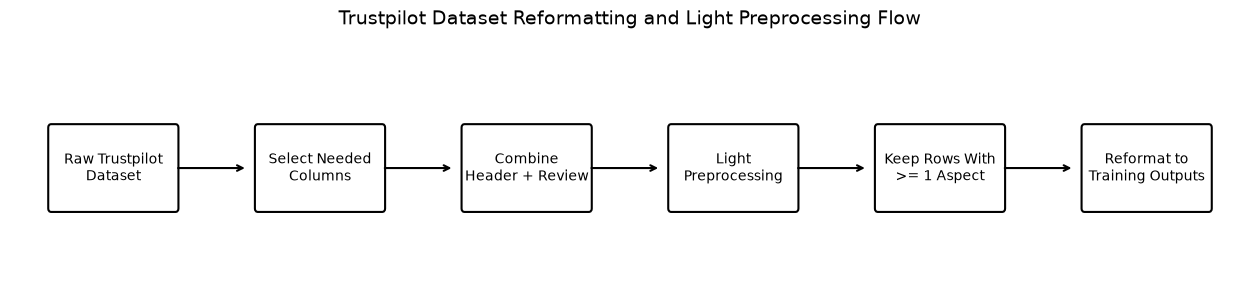

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\01_flowchart_trustpilot_reformatting.png


In [17]:
steps = [
    'Raw Trustpilot\nDataset',
    'Select Needed\nColumns',
    'Combine\nHeader + Review',
    'Light\nPreprocessing',
    'Keep Rows With\n>= 1 Aspect',
    'Reformat to\nTraining Outputs'
]

fig, ax = plt.subplots(figsize=(16, 3))
ax.set_xlim(0, len(steps) * 2)
ax.set_ylim(0, 2)
ax.axis('off')

for i, step in enumerate(steps):
    x = 0.4 + i * 2
    box = FancyBboxPatch((x, 0.55), 1.2, 0.7, boxstyle='round,pad=0.03', linewidth=1.5, fill=False)
    ax.add_patch(box)
    ax.text(x + 0.6, 0.9, step, ha='center', va='center', fontsize=10)
    if i < len(steps) - 1:
        ax.annotate('', xy=(x + 1.9, 0.9), xytext=(x + 1.2, 0.9), arrowprops=dict(arrowstyle='->', lw=1.5))

ax.set_title('Trustpilot Dataset Reformatting and Light Preprocessing Flow', fontsize=14, pad=12)
flowchart_path = FIGURE_DIR / '01_flowchart_trustpilot_reformatting.png'
fig.savefig(flowchart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', flowchart_path.resolve())


### 10.2 Filtering summary

,stage,count
0,Original review rows,3500
1,Kept review rows,2782
2,Dropped review rows,718
3,Aspect-sentiment rows,6272


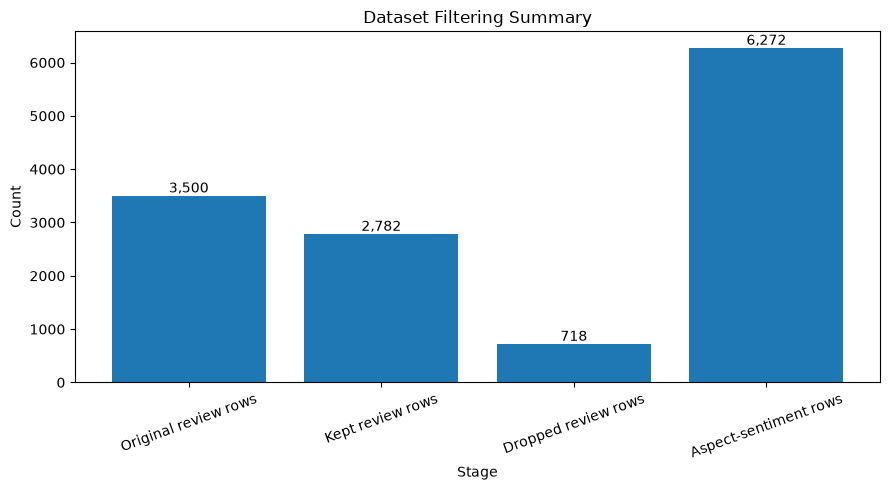

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\02_filtering_summary.png


In [18]:
filtering_summary = pd.DataFrame({
    'stage': ['Original review rows', 'Kept review rows', 'Dropped review rows', 'Aspect-sentiment rows'],
    'count': [len(df), len(df_kept), len(df_dropped), len(long_df)]
})

display(filtering_summary)

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(filtering_summary['stage'], filtering_summary['count'])
ax.set_title('Dataset Filtering Summary')
ax.set_xlabel('Stage')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=20)
for i, v in enumerate(filtering_summary['count']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
filtering_chart_path = FIGURE_DIR / '02_filtering_summary.png'
fig.savefig(filtering_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', filtering_chart_path.resolve())


### 10.3 Emoji cleaning comparison

,status,count
0,Rows with emoji before cleaning,145
1,Rows with emoji after cleaning,0


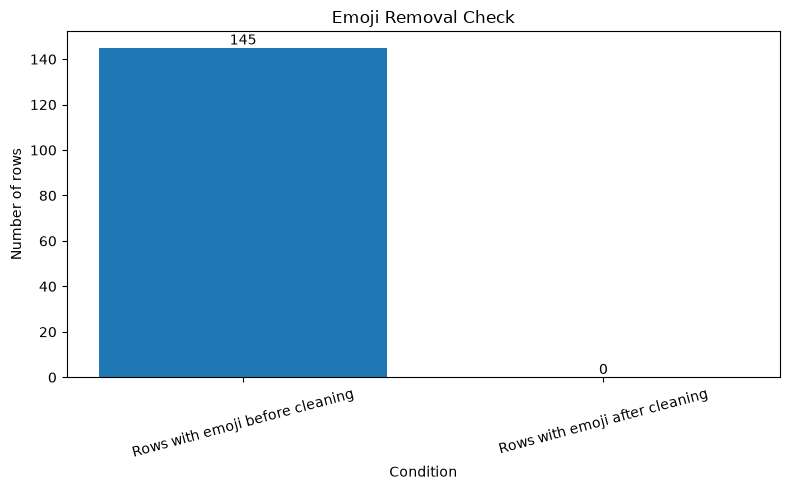

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\03_emoji_removal_check.png


In [19]:
emoji_summary = pd.DataFrame({
    'status': ['Rows with emoji before cleaning', 'Rows with emoji after cleaning'],
    'count': [int(emoji_mask_text.sum()), int(emoji_after_mask.sum())]
})

display(emoji_summary)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(emoji_summary['status'], emoji_summary['count'])
ax.set_title('Emoji Removal Check')
ax.set_xlabel('Condition')
ax.set_ylabel('Number of rows')
ax.tick_params(axis='x', rotation=15)
for i, v in enumerate(emoji_summary['count']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
emoji_chart_path = FIGURE_DIR / '03_emoji_removal_check.png'
fig.savefig(emoji_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', emoji_chart_path.resolve())


### 10.4 Aspect frequency distribution

,aspect,count
0,Shipping,1515
1,Trust,1181
2,Item_quality,745
3,Customer_service,649
4,Pricing,465
5,Product_features,316
6,Refund_process,278
7,Product_availability,238
8,App_experience,221
9,Delivered_product_status,212


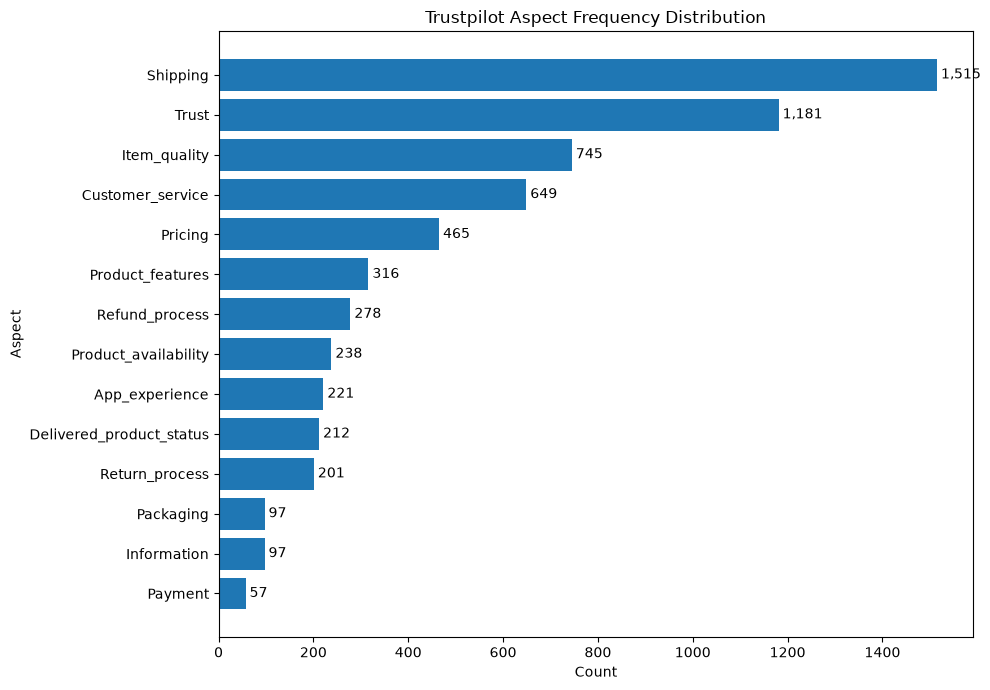

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\04_aspect_frequency_distribution.png


In [20]:
aspect_distribution_sorted = aspect_distribution.sort_values('count', ascending=True).reset_index(drop=True)
display(aspect_distribution.sort_values('count', ascending=False))

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(aspect_distribution_sorted['aspect'], aspect_distribution_sorted['count'])
ax.set_title('Trustpilot Aspect Frequency Distribution')
ax.set_xlabel('Count')
ax.set_ylabel('Aspect')
for i, v in enumerate(aspect_distribution_sorted['count']):
    ax.text(v, i, f' {v:,}', va='center')
plt.tight_layout()
aspect_chart_path = FIGURE_DIR / '04_aspect_frequency_distribution.png'
fig.savefig(aspect_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', aspect_chart_path.resolve())


### 10.5 Binary aspect-level sentiment distribution

,aspect_sentiment,count
0,Positive,3806
1,Negative,2466


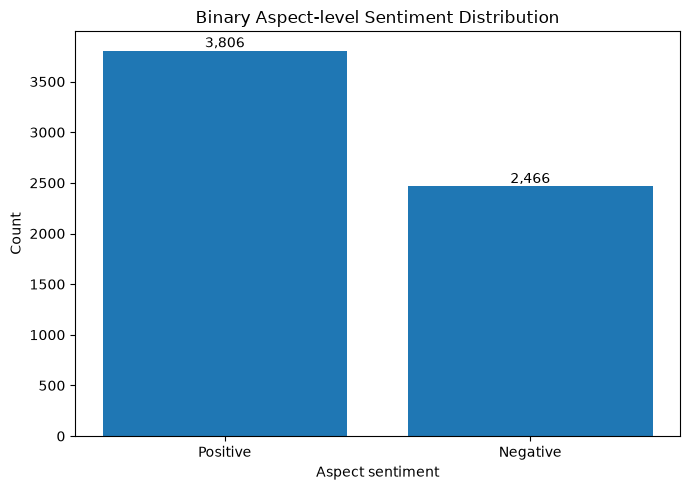

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\05_binary_aspect_sentiment_distribution.png


In [21]:
display(sentiment_distribution)

fig, ax = plt.subplots(figsize=(7, 5))
ax.bar(sentiment_distribution['aspect_sentiment'], sentiment_distribution['count'])
ax.set_title('Binary Aspect-level Sentiment Distribution')
ax.set_xlabel('Aspect sentiment')
ax.set_ylabel('Count')
for i, v in enumerate(sentiment_distribution['count']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
plt.tight_layout()
binary_sentiment_chart_path = FIGURE_DIR / '05_binary_aspect_sentiment_distribution.png'
fig.savefig(binary_sentiment_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', binary_sentiment_chart_path.resolve())


### 10.6 Aspect by sentiment distribution

aspect_sentiment,Negative,Positive
aspect,,
Product_availability,20.0,218.0
Payment,40.0,17.0
Pricing,49.0,416.0
App_experience,51.0,170.0
Information,82.0,15.0
Return_process,86.0,115.0
Packaging,97.0,0.0
Item_quality,117.0,628.0
Product_features,141.0,175.0


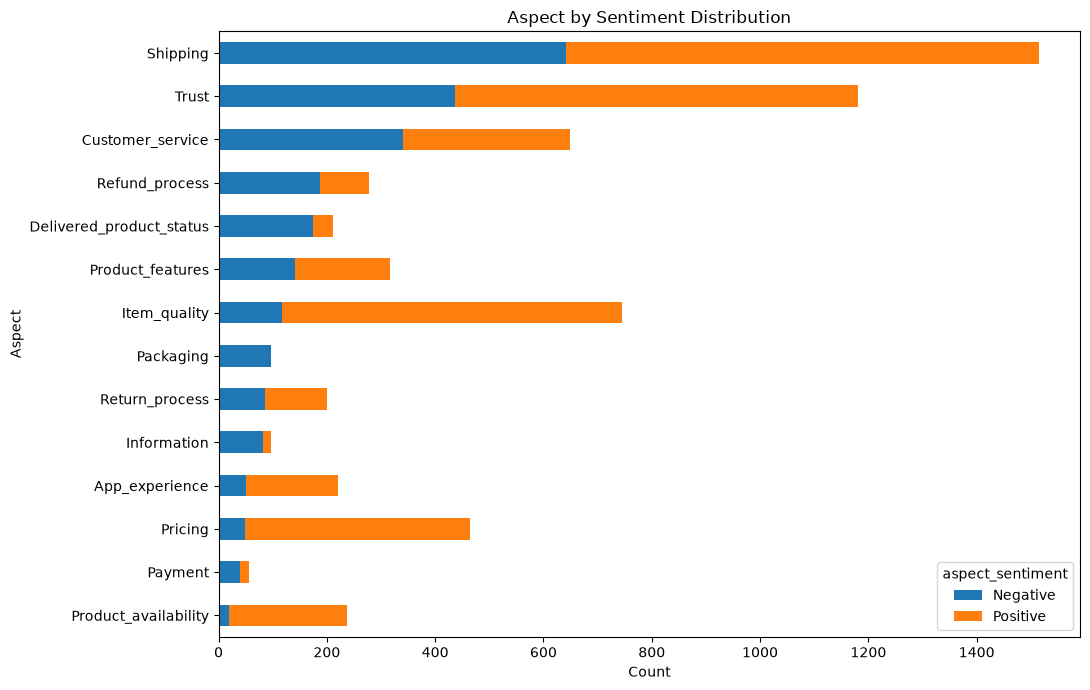

Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\06_aspect_by_sentiment_distribution.png


In [23]:
aspect_sentiment_pivot = (
    aspect_sentiment_distribution
    .pivot(index='aspect', columns='aspect_sentiment', values='count')
    .fillna(0)
)

ordered_cols = [col for col in ['Negative', 'Positive'] if col in aspect_sentiment_pivot.columns]
other_cols = [col for col in aspect_sentiment_pivot.columns if col not in ordered_cols]
aspect_sentiment_pivot = aspect_sentiment_pivot[ordered_cols + other_cols]
aspect_sentiment_pivot = aspect_sentiment_pivot.sort_values(by=ordered_cols[0] if ordered_cols else aspect_sentiment_pivot.columns[0], ascending=True)

display(aspect_sentiment_pivot)

fig, ax = plt.subplots(figsize=(11, 7))
aspect_sentiment_pivot.plot(kind='barh', stacked=True, ax=ax)
ax.set_title('Aspect by Sentiment Distribution')
ax.set_xlabel('Count')
ax.set_ylabel('Aspect')
plt.tight_layout()
aspect_sentiment_chart_path = FIGURE_DIR / '06_aspect_by_sentiment_distribution.png'
fig.savefig(aspect_sentiment_chart_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', aspect_sentiment_chart_path.resolve())


### 10.7 Summary table for documentation

In [24]:
documentation_summary = pd.DataFrame([
    ['Original review rows', len(df)],
    ['Kept review rows', len(df_kept)],
    ['Dropped review rows', len(df_dropped)],
    ['Aspect-sentiment rows', len(long_df)],
    ['Rows with emoji before cleaning', int(emoji_mask_text.sum())],
    ['Rows with emoji after cleaning', int(emoji_after_mask.sum())],
    ['Number of Trustpilot aspects', len(ASPECT_COLS)],
], columns=['Metric', 'Value'])

documentation_summary_path = FIGURE_DIR / '07_documentation_summary.csv'
documentation_summary.to_csv(documentation_summary_path, index=False, encoding='utf-8-sig')
display(documentation_summary)
print('Saved:', documentation_summary_path.resolve())


,Metric,Value
0,Original review rows,3500
1,Kept review rows,2782
2,Dropped review rows,718
3,Aspect-sentiment rows,6272
4,Rows with emoji before cleaning,145
5,Rows with emoji after cleaning,0
6,Number of Trustpilot aspects,14


Saved: C:\Users\Lenovo\Documents\Skripsi\dataset\phase1\trustpilot_reformatted_output\figures\07_documentation_summary.csv
